#EDA - Exploration Dataset MoocData XuetangX
# Analyse exploratoire et vérification anomalies train/test

# MONTAGE GOOGLE DRIVE


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. SETUP INITIAL

In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [3]:
# Chemins de base et des fichiers
base_path = '/content/drive/MyDrive/MOOC_Recommandation_Adaptative/data/raw/OULAD'

# 2. CHARGEMENT DES DATASETS

In [4]:
print(" Chargement des datasets OULAD...")

try:
    df_assessments = pd.read_csv(f"{base_path}/assessments.csv")
    df_courses = pd.read_csv(f"{base_path}/courses.csv")
    df_student_assessments = pd.read_csv(f"{base_path}/studentAssessment.csv")
    df_student_info = pd.read_csv(f"{base_path}/studentInfo.csv")
    df_student_registration = pd.read_csv(f"{base_path}/studentRegistration.csv")
    df_student_vle = pd.read_csv(f"{base_path}/studentVle.csv")
    df_vle = pd.read_csv(f"{base_path}/vle.csv")

    print(" Tous les datasets ont été chargés avec succès.")

except FileNotFoundError as e:
    print(f" Erreur: Un fichier n'a pas été trouvé. Veuillez vérifier les chemins d'accès.")
    print(e)
    exit()

 Chargement des datasets OULAD...
 Tous les datasets ont été chargés avec succès.


# 3. EXPLORATION DE CHAQUE FICHIER

In [5]:
def explore_dataframe(df, name):
    """Affiche un résumé de l'exploration pour un DataFrame."""
    print(f"\n====================  Exploration: {name} ====================")
    print("Aperçu des données:")
    print(df.head())
    print("\nℹ Informations et types de données:")
    df.info()
    print("\n Statistiques de base:")
    print(df.describe(include='all'))
    print("-" * 60)

explore_dataframe(df_assessments, "assessments.csv")
explore_dataframe(df_courses, "courses.csv")
explore_dataframe(df_student_assessments, "studentAssessment.csv")
explore_dataframe(df_student_info, "studentInfo.csv")
explore_dataframe(df_student_registration, "studentRegistration.csv")
explore_dataframe(df_student_vle, "studentVle.csv")
explore_dataframe(df_vle, "vle.csv")



====================  Exploration: assessments.csv ====================
Aperçu des données:
  code_module code_presentation  id_assessment assessment_type   date  weight
0         AAA             2013J           1752             TMA   19.0    10.0
1         AAA             2013J           1753             TMA   54.0    20.0
2         AAA             2013J           1754             TMA  117.0    20.0
3         AAA             2013J           1755             TMA  166.0    20.0
4         AAA             2013J           1756             TMA  215.0    30.0

ℹ Informations et types de données:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   code_module        206 non-null    object 
 1   code_presentation  206 non-null    object 
 2   id_assessment      206 non-null    int64  
 3   assessment_type    206 non-null    object 
 4   date 

# 4. ANALYSE SPÉCIFIQUE

In [6]:
# Analyse de la variable cible 'final_result' dans studentInfo.csv
print("\n====================  Analyse de la variable cible: final_result ====================")
target_distribution = df_student_info['final_result'].value_counts(normalize=True).mul(100)
print(" Distribution des résultats finaux des étudiants:")
print(target_distribution)


====================  Analyse de la variable cible: final_result ====================
 Distribution des résultats finaux des étudiants:
final_result
Pass           37.925321
Withdrawn      31.160065
Fail           21.636548
Distinction     9.278066
Name: proportion, dtype: float64


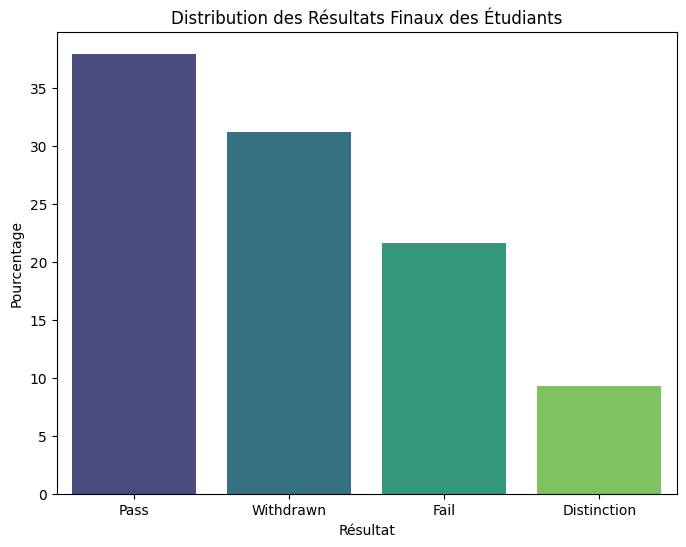

In [7]:
# Visualisation de la distribution
plt.figure(figsize=(8, 6))
sns.barplot(x=target_distribution.index, y=target_distribution.values, palette='viridis')
plt.title('Distribution des Résultats Finaux des Étudiants')
plt.ylabel('Pourcentage')
plt.xlabel('Résultat')
plt.show()

In [8]:
# Définition des classes de succès, d'échec et d'abandon
print("\n Identification des classes pour la tâche de prédiction:")
# La classe 'Withdrawn' (abandon) est la classe d'intérêt.
# On peut considérer 'Fail', 'Pass', et 'Distinction' comme des succès ou des échecs.
# Pour le projet, nous binariserons le résultat en 'Abandon' (Withdrawn) et 'Succès' (Pass/Fail/Distinction)
df_student_info['is_withdrawn'] = df_student_info['final_result'].apply(lambda x: 1 if x == 'Withdrawn' else 0)
print(df_student_info['is_withdrawn'].value_counts())


 Identification des classes pour la tâche de prédiction:
is_withdrawn
0    22437
1    10156
Name: count, dtype: int64


In [9]:
# Analyse du déséquilibre
abandon_count = df_student_info['is_withdrawn'].sum()
total_students = len(df_student_info)
print(f"\n Taux d'abandon: {abandon_count / total_students * 100:.2f}%")


 Taux d'abandon: 31.16%


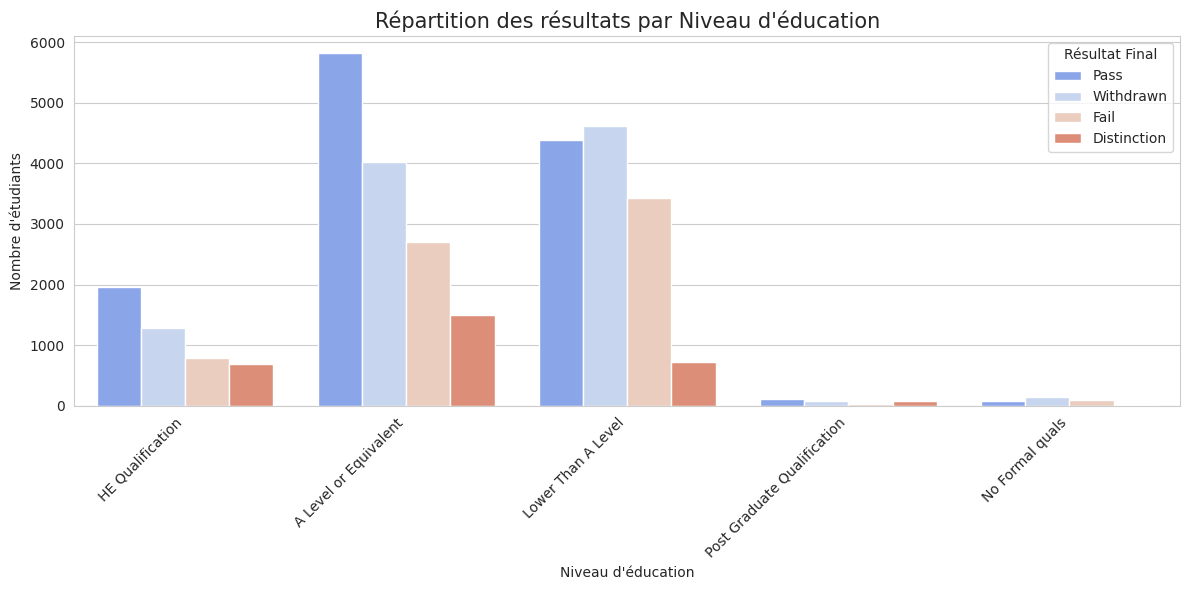

In [12]:
# Configuration de l'esthétique
sns.set_style("whitegrid")

# 1. Relation entre Niveau d'éducation et Résultat
plt.figure(figsize=(12, 6))
# On trie pour avoir un ordre logique si possible, sinon l'ordre par défaut ira
sns.countplot(data=df_student_info, x='highest_education', hue='final_result', palette='coolwarm')
plt.title('Répartition des résultats par Niveau d\'éducation', fontsize=15)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Niveau d\'éducation')
plt.ylabel('Nombre d\'étudiants')
plt.legend(title='Résultat Final')
plt.tight_layout()
plt.show()

# "Ce graphique montre que les étudiants avec un niveau d'éducation initial plus faible (ex: No Formal quals)
# semblent avoir des taux d'échec/abandon plus élevés, ce qui sera une feature importante pour le modèle."

Calcul des clics totaux par étudiant...


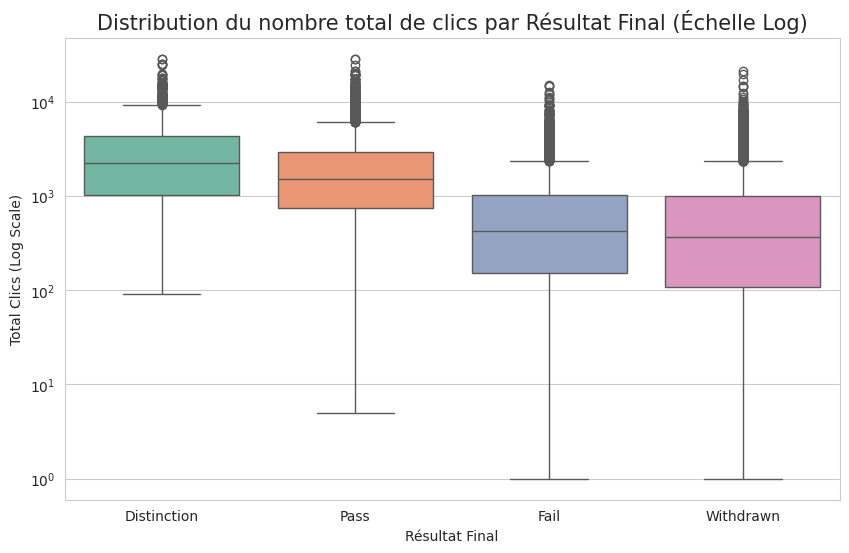

In [13]:
# 1. Agréger les clics par étudiant
print("Calcul des clics totaux par étudiant...")
clicks_per_student = df_student_vle.groupby('id_student')['sum_click'].sum().reset_index()
clicks_per_student.columns = ['id_student', 'total_clicks']

# 2. Fusionner avec les infos étudiants (seulement ceux qui ont des clics)
df_clicks_info = pd.merge(df_student_info, clicks_per_student, on='id_student', how='inner')

# 3. Visualisation (Boxplot pour voir les distributions et outliers)
plt.figure(figsize=(10, 6))
# On utilise log scale car certains ont 0 clics et d'autres 20,000
sns.boxplot(x='final_result', y='total_clicks', data=df_clicks_info, palette='Set2', order=['Distinction', 'Pass', 'Fail', 'Withdrawn'])
plt.yscale('log') # Échelle logarithmique pour mieux voir les différences
plt.title('Distribution du nombre total de clics par Résultat Final (Échelle Log)', fontsize=15)
plt.ylabel('Total Clics (Log Scale)')
plt.xlabel('Résultat Final')
plt.show()


# "On observe clairement ici une corrélation : les étudiants 'Withdrawn' (Abandon) ont une médiane de clics
# drastiquement inférieure aux 'Pass' ou 'Distinction'. Cela valide l'utilisation des données VLE pour la prédiction."

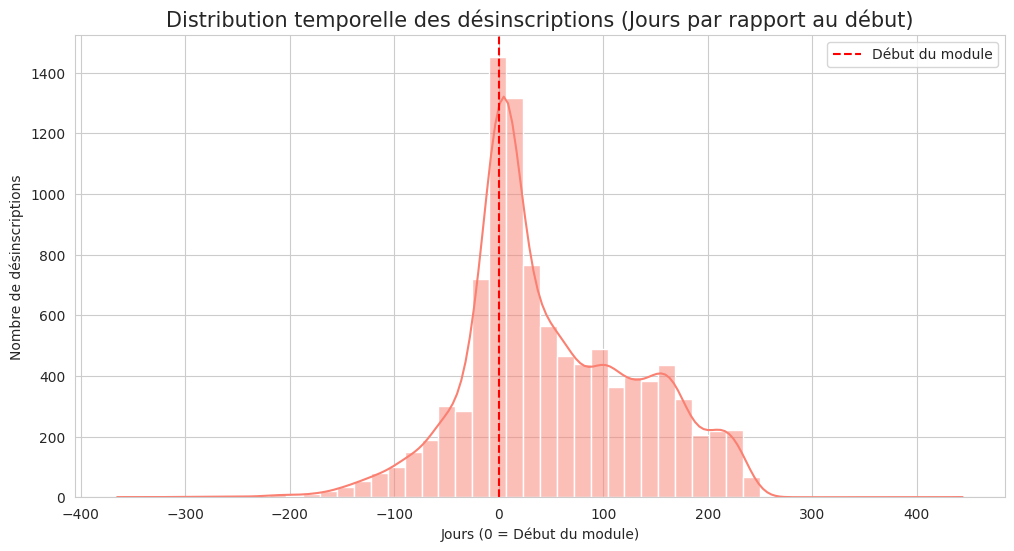

In [14]:
# Filtrer uniquement ceux qui se sont désinscrits (date_unregistration existe)
unreg_data = df_student_registration.dropna(subset=['date_unregistration'])

plt.figure(figsize=(12, 6))
sns.histplot(data=unreg_data, x='date_unregistration', bins=50, kde=True, color='salmon')
plt.axvline(x=0, color='red', linestyle='--', label='Début du module')
plt.title('Distribution temporelle des désinscriptions (Jours par rapport au début)', fontsize=15)
plt.xlabel('Jours (0 = Début du module)')
plt.ylabel('Nombre de désinscriptions')
plt.legend()
plt.show()

# "Nous voyons un pic massif d'abandons au tout début du semestre (autour de 0).
# Cela souligne l'importance du problème 'Cold Start' : il faut identifier les étudiants à risque très tôt."

# 5. VÉRIFICATION DES IDENTIFIANTS

In [10]:
print("\n====================  Vérification des clés de jointure ====================")
print(f"Nombre d'étudiants uniques dans studentInfo: {df_student_info['id_student'].nunique()}")
print(f"Nombre d'étudiants uniques dans studentVle: {df_student_vle['id_student'].nunique()}")
print(f"Nombre de modules uniques: {df_courses['code_module'].nunique()}")
print(f"Nombre de présentations uniques: {df_courses['code_presentation'].nunique()}")


====================  Vérification des clés de jointure ====================
Nombre d'étudiants uniques dans studentInfo: 28785
Nombre d'étudiants uniques dans studentVle: 26074
Nombre de modules uniques: 7
Nombre de présentations uniques: 4


In [11]:
# Conclusion
print("\n Exploration terminée. Les données sont prêtes pour le feature engineering.")
print("La prochaine étape consistera à créer des caractéristiques à partir de ces fichiers.")


 Exploration terminée. Les données sont prêtes pour le feature engineering.
La prochaine étape consistera à créer des caractéristiques à partir de ces fichiers.
